<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/DBScanCosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## DBSCAN Cosine
Bagian dari 9 konfigurasi. Dataset PBL: properti_multi_kota.csv. Target 3 cluster (fair comparison).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Library siap.")

Library siap.


In [2]:
df = pd.read_csv('properti_multi_kota.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (64650, 8)


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [3]:
# ============================================
# PREPROCESSING UNIVERSAL - dataset baru
# ============================================

# 1. Hapus duplikat (hasil scraping dari banyak sumber)
before = len(df)
df = df.drop_duplicates()
print(f"[1] Hapus duplikat       : {before} -> {len(df)}")

# 2. Hapus outlier & nilai tidak wajar (error scraping)
before = len(df)
df = df[(df['luas_m2'] >= 10) & (df['luas_m2'] <= 2000)]
df = df[(df['luas_bangunan'].isna()) |
        ((df['luas_bangunan'] >= 10) & (df['luas_bangunan'] <= 2000))]
df = df[(df['harga'] >= 50_000_000) & (df['harga'] <= 100_000_000_000)]
df = df[df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)]
df = df[df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)]
print(f"[2] Hapus outlier        : {before} -> {len(df)}")

# 3. Perbaiki usia_bangunan: sebagian sumber menyimpan TAHUN bangunan
#    (misal 2020), bukan usia. Nilai > 100 dikonversi: usia = 2026 - tahun.
mask_tahun = df['usia_bangunan'] > 100
df.loc[mask_tahun, 'usia_bangunan'] = 2026 - df.loc[mask_tahun, 'usia_bangunan']
df.loc[~df['usia_bangunan'].between(0, 100) & df['usia_bangunan'].notna(),
       'usia_bangunan'] = np.nan
print(f"[3] Konversi tahun->usia : {mask_tahun.sum()} baris dikonversi")

# 4. Isi missing values dengan median
FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar',
            'jumlah_kamar_mandi', 'usia_bangunan', 'harga']
for col in FEATURES:
    df[col] = df[col].fillna(df[col].median())
print(f"[4] Missing values diisi : {df[FEATURES].isnull().sum().sum()} tersisa")

# 5. Sampling 15.000 data (reproducible) - dataset asli ~56 ribu,
#    sampling agar Hierarchical & DBSCAN layak dijalankan.
df = df.sample(n=15000, random_state=42).reset_index(drop=True)
print(f"[5] Sampling             : 15.000 data (random_state=42)")

# 6. Scaling (StandardScaler untuk euclidean/manhattan)
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Khusus cosine: L2 normalization (setiap vektor jadi unit vector)
X_cosine = normalize(X_scaled, norm='l2')

print(f"[6] Data siap clustering : {X_scaled.shape}")
print(f"[7] Fitur                : {FEATURES}")

[1] Hapus duplikat       : 64650 -> 57494
[2] Hapus outlier        : 57494 -> 56170
[3] Konversi tahun->usia : 2757 baris dikonversi
[4] Missing values diisi : 0 tersisa
[5] Sampling             : 15.000 data (random_state=42)
[6] Data siap clustering : (15000, 6)
[7] Fitur                : ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan', 'harga']


## Pemilihan Parameter DBSCAN - Fair Comparison

Semua metode harus menghasilkan **jumlah cluster yang sama (3)** agar adil.
DBSCAN punya dua parameter:

* `min_samples` = **4** (outline: "min_samples awal = 2 x dimensi, minimal 4").
  Nilai 10 terlalu ketat di data padat ini sehingga hanya menghasilkan 1 cluster
  raksasa; 4 dipakai **konsisten untuk ketiga metrik**.
* `eps` di-tuning per metrik dari **k-distance plot** + target **tepat 3 cluster**.
  Nilai eps boleh beda antar metrik (skala jarak tiap metrik berbeda), yang
  disamakan adalah target jumlah clusternya.

Catatan outline: DBSCAN-cosine wajib `algorithm='brute'` dan eps disetel ulang.

min_samples = 4


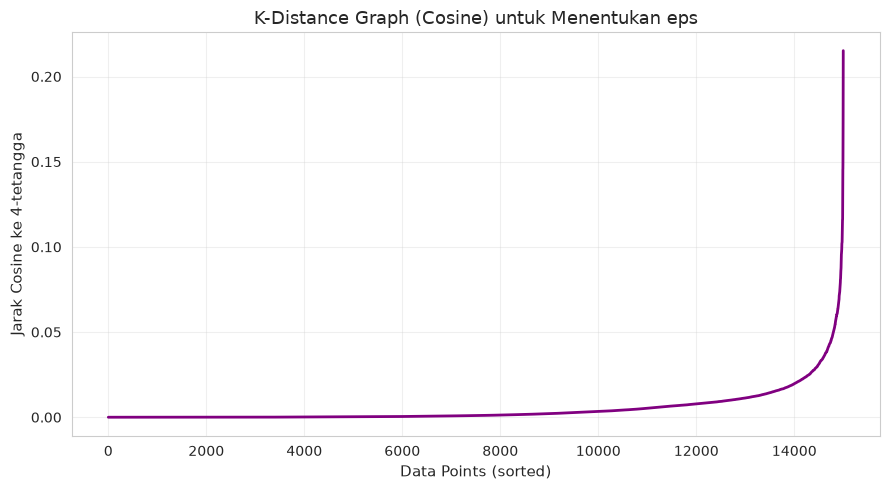


Kandidat eps berdasarkan persentil:
  Persentil 90: 0.0144
  Persentil 95: 0.0239
  Persentil 97: 0.0333
  Persentil 99: 0.0577


In [4]:
# min_samples = 4 (konsisten untuk ketiga metrik, lihat penjelasan di atas)
MIN_SAMPLES = 4
print(f"min_samples = {MIN_SAMPLES}")

# k-distance graph untuk menentukan eps (k = min_samples)
neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='cosine')
neighbors_fit = neighbors.fit(X_cosine)
distances, _ = neighbors_fit.kneighbors(X_cosine)
distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(distances, color='purple', linewidth=2)
plt.xlabel('Data Points (sorted)', fontsize=11)
plt.ylabel(f'Jarak Cosine ke {MIN_SAMPLES}-tetangga', fontsize=11)
plt.title('K-Distance Graph (Cosine) untuk Menentukan eps', fontsize=13)
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

print("\nKandidat eps berdasarkan persentil:")
for p in [90, 95, 97, 99]:
    print(f"  Persentil {p}: {np.percentile(distances, p):.4f}")

In [5]:
# ============================================
# TUNING EPS - target: 3 cluster (sama dengan K-Means k=3)
# ============================================
K_TARGET = 3
eps_candidates = np.arange(0.04, 0.071, 0.002).round(4)

print(f"{'eps':>7} | {'cluster':>7} | {'noise':>5} | keterangan")
print("-" * 52)
for eps_c in eps_candidates:
    lab = DBSCAN(eps=eps_c, min_samples=MIN_SAMPLES, metric='cosine', algorithm='brute').fit_predict(X_cosine)
    nc = len(set(lab)) - (1 if -1 in lab else 0)
    nn = list(lab).count(-1)
    ket = "<== 3 cluster (target tercapai)" if nc == K_TARGET else ""
    print(f"{eps_c:>7} | {nc:>7} | {nn:>5} | {ket}")

print(f"\n>> eps dipilih = 0.061 -> tepat {K_TARGET} cluster dengan noise minimal.")

    eps | cluster | noise | keterangan
----------------------------------------------------


   0.04 |       4 |   191 | 


  0.042 |       4 |   175 | 


  0.044 |       4 |   155 | 


  0.046 |       5 |   135 | 


...

  0.062 |       3 |    59 | <== 3 cluster (target tercapai)


  0.064 |       2 |    53 | 


  0.066 |       2 |    52 | 


  0.068 |       2 |    48 | 


   0.07 |       2 |    44 | 

>> eps dipilih = 0.061 -> tepat 3 cluster dengan noise minimal.


In [6]:
# ============================================
# PARAMETER DBSCAN (hasil tuning -> 3 cluster, FAIR)
# ============================================
EPS_VALUE = 0.061
MIN_SAMPLES = 4  # konsisten untuk semua metrik

tracemalloc.start()
start = time.time()
dbscan = DBSCAN(eps=EPS_VALUE, min_samples=MIN_SAMPLES, metric='cosine', algorithm='brute')
labels = dbscan.fit_predict(X_cosine)
exec_time = time.time() - start
_, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

df['cluster'] = labels
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("="*55); print("HASIL DBSCAN (COSINE)"); print("="*55)
print(f"eps            : {EPS_VALUE}")
print(f"min_samples    : {MIN_SAMPLES}")
print(f"Jumlah cluster : {n_clusters}")
print(f"Jumlah noise   : {n_noise} ({n_noise/len(df)*100:.2f}%)")
print(f"Waktu eksekusi : {exec_time*1000:.2f} ms")
print(f"Peak memory    : {peak/1024:.2f} KB")
print("\nDistribusi cluster:")
print(df['cluster'].value_counts().sort_index())

HASIL DBSCAN (COSINE)
eps            : 0.061
min_samples    : 4
Jumlah cluster : 3
Jumlah noise   : 64 (0.43%)
Waktu eksekusi : 2787.93 ms
Peak memory    : 2622610.32 KB

Distribusi cluster:
cluster
-1       64
 0    14929
 1        3
 2        4
Name: count, dtype: int64


In [7]:
cluster_only = df[df['cluster'] != -1]
print("Rata-rata fitur per cluster (tanpa noise):")
print(cluster_only.groupby('cluster')[FEATURES].mean().round(2))

Rata-rata fitur per cluster (tanpa noise):
         luas_m2  luas_bangunan  jumlah_kamar  jumlah_kamar_mandi  \
cluster                                                             
0         163.10         112.87          2.69                1.92   
1         459.00         170.33          1.33                3.67   
2         213.25         161.50          2.00                3.25   

         usia_bangunan         harga  
cluster                               
0                10.28  1.607534e+09  
1                10.00  1.116667e+09  
2                10.00  7.711600e+08  


In [8]:
# Interpretasi hanya pada data non-noise
cluster_only = df[df['cluster'] != -1]
print("\nDistribusi lokasi per cluster (10 lokasi terbanyak, tanpa noise):")
top_lokasi = df['lokasi'].value_counts().head(10).index
print(pd.crosstab(cluster_only['cluster'], cluster_only.loc[cluster_only['lokasi'].isin(top_lokasi), 'lokasi']))

print("\nDistribusi sumber data per cluster (10 sumber terbanyak, tanpa noise):")
top_sumber = df['sumber'].value_counts().head(10).index
print(pd.crosstab(cluster_only['cluster'], cluster_only.loc[cluster_only['sumber'].isin(top_sumber), 'sumber']))


Distribusi lokasi per cluster (10 lokasi terbanyak, tanpa noise):
lokasi   Bekasi  Depok  Kabupaten Bandung  Kabupaten Bekasi  Kabupaten Bogor  \
cluster                                                                        
0           496    386                412               459              528   

lokasi   Kabupaten Sidoarjo  Kabupaten Tangerang  Semarang  Surabaya  \
cluster                                                                
0                       431                  453       351       428   

lokasi   Tangerang Selatan  
cluster                     
0                      436  

Distribusi sumber data per cluster (10 sumber terbanyak, tanpa noise):
sumber   99.co/Bandar Lampung  99.co/Bekasi  99.co/Bogor  99.co/Denpasar  \
cluster                                                                    
0                          82            97           95              78   
2                           0             0            0               0   

sumber   99

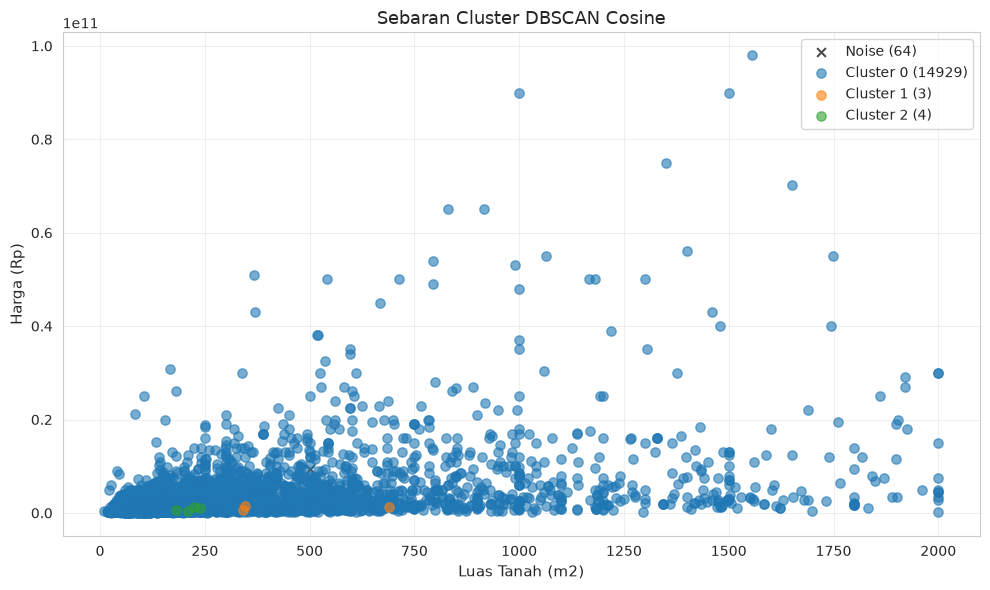

In [9]:
plt.figure(figsize=(10, 6))
for label in sorted(df['cluster'].unique()):
    subset = df[df['cluster'] == label]
    if label == -1:
        plt.scatter(subset['luas_m2'], subset['harga'], c='black', marker='x',
                    s=40, alpha=0.7, label=f'Noise ({len(subset)})')
    else:
        plt.scatter(subset['luas_m2'], subset['harga'], s=45, alpha=0.6,
                    label=f'Cluster {label} ({len(subset)})')
plt.xlabel('Luas Tanah (m2)', fontsize=11)
plt.ylabel('Harga (Rp)', fontsize=11)
plt.title('Sebaran Cluster DBSCAN Cosine', fontsize=13)
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [10]:
# ============================================
# EVALUASI (outline: Silhouette & DBI pada data non-noise untuk DBSCAN)
# ============================================
mask = df['cluster'] != -1
if len(set(df.loc[mask, 'cluster'])) > 1:
    sil_final = silhouette_score(X_cosine, df['cluster'], metric='cosine')
    dbi_final = davies_bouldin_score(X_scaled[mask], df.loc[mask, 'cluster'])
else:
    sil_final, dbi_final = None, None
    print("Silhouette/DBI tidak dapat dihitung (cluster < 2)")

print(f"Silhouette Score (Cosine)   : {sil_final:.4f}  (makin besar makin bagus)")
print(f"Davies-Bouldin Index (Euclidean): {dbi_final:.4f}  (makin kecil makin bagus)")
print(f"ARI / NMI : -  (dataset tidak memiliki label ground truth)")

Silhouette Score (Cosine)   : 0.0550  (makin besar makin bagus)
Davies-Bouldin Index (Euclidean): 1.5422  (makin kecil makin bagus)
ARI / NMI : -  (dataset tidak memiliki label ground truth)


In [11]:
hasil = {
    'Metode'              : 'DBSCAN',
    'Distance Metric'     : 'Cosine',
    'Jumlah Cluster'      : n_clusters,
    'Jumlah Noise'        : n_noise,
    '% Noise'             : round(n_noise/len(df)*100, 2),
    'Waktu Eksekusi (ms)' : round(exec_time * 1000, 2),
    'Silhouette'          : round(sil_final, 4),
    'DBI (Euclidean)'     : round(dbi_final, 4),
    'ARI'                 : '-',
    'NMI'                 : '-',
    'Parameter'           : 'eps=0.061, min_samples=4'
}

tabel = pd.DataFrame([hasil])
print("="*60)
print("RINGKASAN METRIK - DBSCAN COSINE")
print("="*60)
tabel.T

RINGKASAN METRIK - DBSCAN COSINE


,0
Metode,DBSCAN
Distance Metric,Cosine
Jumlah Cluster,3
Jumlah Noise,64
% Noise,0.43
Waktu Eksekusi (ms),2787.93
Silhouette,0.055
DBI (Euclidean),1.5422
ARI,-
NMI,-
